
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/12_Lab_PinnsI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


#Diferenciación automática

In [2]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  # valor: sin(a);  derivada: cos(a)·da   (corregido: antes devolvía cos(a) como valor)
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  # valor: cos(a);  derivada: -sin(a)·da   (corregido: antes devolvía -sin(a) como valor y -cos(a)·da como derivada)
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da

> **Corrección.** En la versión original, `seno` devolvía $\cos(a)$ como valor y `coseno` devolvía $-\sin(a)$ como valor y $-\cos(a)\,da$ como derivada. Las reglas correctas en modo *forward* (números duales) son $(\sin a)' = \cos(a)\,a'$ y $(\cos a)' = -\sin(a)\,a'$. La gráfica de la celda siguiente (`np.sin(x)` vs `seno(x, 1)[0]`) permite comprobarlo: ahora las dos curvas coinciden.


Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [3]:
x = 2.2

In [4]:
derivadaX = producto(x, 1, x, 1)
derivadaX

(4.840000000000001, 4.4)

In [5]:
# Verificación de f(x) = (2x+1)^2  ->  f'(x) = 4(2x+1)
x = 2.2
print("x^2:      valor =", x**2, "  derivada exacta =", 2*x)
print("(2x+1)^2: valor =", (2*x+1)**2, "  derivada exacta =", 4*(2*x+1))

x^2:      valor = 4.840000000000001   derivada exacta = 4.4
(2x+1)^2: valor = 29.160000000000004   derivada exacta = 21.6


In [6]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(29.160000000000004, 21.6)

In [7]:
x = np.linspace(0, 2*np.pi)

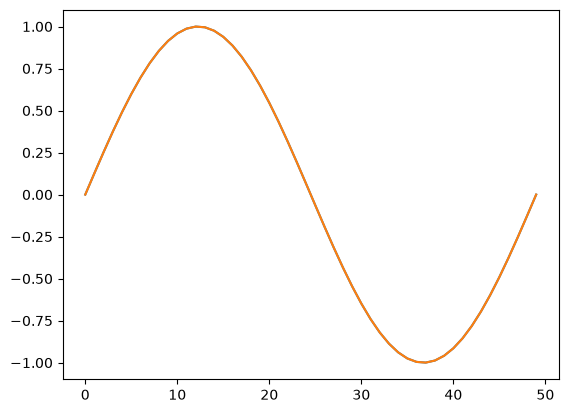

In [8]:
plt.plot(np.sin(x))
plt.plot(seno(x, 1)[0])

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [9]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

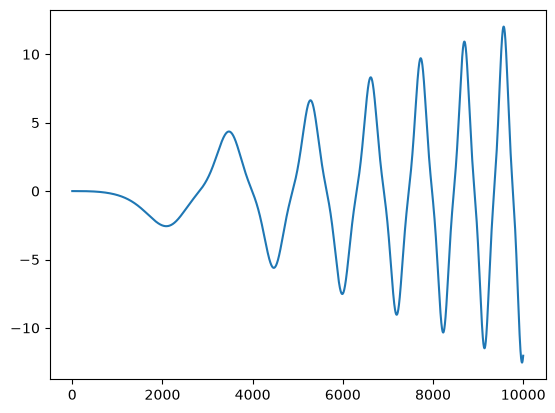

In [10]:
plt.plot(dr)

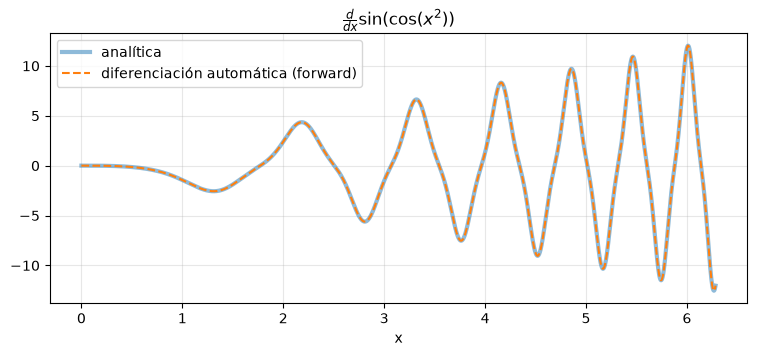

max |error| = 0.0
¿valor correcto? True


In [11]:
# Comparación con la derivada analítica  f'(x) = -2x sin(x²) cos(cos(x²))
df_exacta = -2 * x * np.sin(x**2) * np.cos(np.cos(x**2))
plt.figure(figsize=(9, 3.5))
plt.plot(x, df_exacta, lw=3, alpha=0.5, label="analítica")
plt.plot(x, dr, "--", label="diferenciación automática (forward)")
plt.xlabel("x"); plt.legend(); plt.grid(alpha=.3); plt.title(r"$\frac{d}{dx}\sin(\cos(x^2))$")
plt.show()
print("max |error| =", np.abs(dr - df_exacta).max())
print("¿valor correcto?", np.allclose(r, np.sin(np.cos(x**2))))

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [12]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

In [13]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2




(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [14]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [15]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [16]:
# Verificación con diferencias finitas centradas
x0, h_fd = 0.8, 1e-6
f2 = lambda xx: dneurona(dneurona(xx, 1, w, b)[0], 1, w, b)[0]
print("derivada AD           :", da2)
print("diferencias finitas   :", (f2(x0 + h_fd) - f2(x0 - h_fd)) / (2 * h_fd))

derivada AD           : 0.009549719627467191
diferencias finitas   : 0.009549719626189557


In [17]:
# Lo mismo con la diferenciación automática de PyTorch (modo reverse), que es la que usan las PINNs
import torch
xt = torch.tensor(0.8, requires_grad=True)
a2_t = torch.tanh(w * torch.tanh(w * xt + b) + b)
a2_t.backward()
print("PyTorch autograd      :", xt.grad.item())

PyTorch autograd      : 0.009549721144139767


**Propuesto en clase:** $f(x) = \sin(\cos(x^2)) + \tan(\sin(x^3))$

La tangente se arma como $\tan u = \sin u / \cos u$ usando `division`. La derivada exacta, para comparar, es
$$f'(x) = -2x\,\sin(x^2)\cos(\cos x^2) + 3x^2\cos(x^3)\,\sec^2(\sin x^3).$$


x = 3.14:  f = -1.259705 (exacto -1.259705)
         f' AD = 34.092351   f' exacta = 34.092351


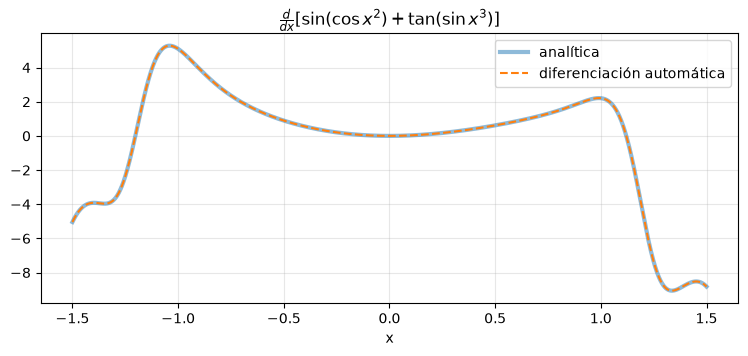

max |error| en [-1.5, 1.5]: 5.329070518200751e-15


In [ ]:
def f_clase(x):
    u1, du1 = producto(x, 1, x, 1)        # x^2
    u2, du2 = producto(u1, du1, x, 1)     # x^3   (ojo: usar du1, no otra variable 'du')
    u3, du3 = coseno(u1, du1)             # cos(x^2)
    u4, du4 = seno(u2, du2)               # sin(x^3)
    u5, du5 = seno(u3, du3)               # sin(cos(x^2))
    u6, du6 = seno(u4, du4)               # sin(sin(x^3))
    u7, du7 = coseno(u4, du4)             # cos(sin(x^3))
    u8, du8 = division(u6, du6, u7, du7)  # tan(sin(x^3))
    return suma(u5, du5, u8, du8)

def df_clase_exacta(x):
    return -2*x*np.sin(x**2)*np.cos(np.cos(x**2)) + 3*x**2*np.cos(x**3)/np.cos(np.sin(x**3))**2

x = 3.14
val, dval = f_clase(x)
print(f"x = {x}:  f = {val:.6f} (exacto {np.sin(np.cos(x**2)) + np.tan(np.sin(x**3)):.6f})")
print(f"         f' AD = {dval:.6f}   f' exacta = {df_clase_exacta(x):.6f}")

xs = np.linspace(-1.5, 1.5, 2000)
_, dxs = f_clase(xs)
plt.figure(figsize=(9, 3.5))
plt.plot(xs, df_clase_exacta(xs), lw=3, alpha=.5, label="analítica")
plt.plot(xs, dxs, "--", label="diferenciación automática")
plt.xlabel("x"); plt.legend(); plt.grid(alpha=.3); plt.title(r"$\frac{d}{dx}[\sin(\cos x^2) + \tan(\sin x^3)]$")
plt.show()
print("max |error| en [-1.5, 1.5]:", np.abs(dxs - df_clase_exacta(xs)).max())


### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [18]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [19]:
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


In [20]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [21]:
# Solución por diferencias finitas (Euler explícito en el tiempo, laplaciano de 5 puntos)
Temperatura[0] = T(X, Y, 0, **params)                 # condición inicial
for n in range(nt - 1):
    Tn = Temperatura[n]
    lap = np.zeros_like(Tn)
    lap[1:-1, 1:-1] = ((Tn[2:, 1:-1] - 2 * Tn[1:-1, 1:-1] + Tn[:-2, 1:-1]) / dx**2 +
                       (Tn[1:-1, 2:] - 2 * Tn[1:-1, 1:-1] + Tn[1:-1, :-2]) / dy**2)
    Temperatura[n + 1] = Tn + params["alpha"] * dt * lap
    # bordes a temperatura constante
    Temperatura[n + 1][0, :] = Temperatura[n + 1][-1, :] = Tb
    Temperatura[n + 1][:, 0] = Temperatura[n + 1][:, -1] = Tb

print(f"dt = {dt:.3f} s  (límite de estabilidad {dt_max:.3f} s),  pasos = {nt}")

dt = 2.674 s  (límite de estabilidad 2.973 s),  pasos = 188


Error máximo de diferencias finitas: 0.0610 °C   (ΔT = 100.0 °C)


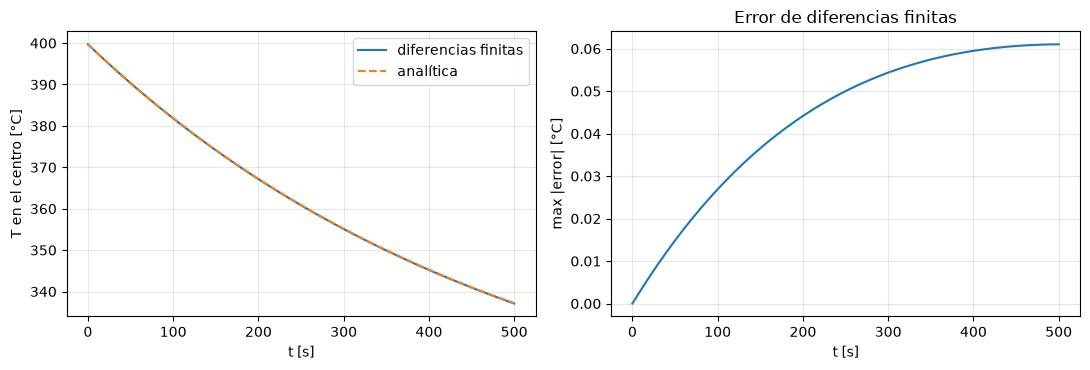

In [22]:
# Comparación diferencias finitas vs solución analítica
T_exacta = np.array([T(X, Y, tk, **params) for tk in t])
err_fd = np.abs(Temperatura - T_exacta)
print(f"Error máximo de diferencias finitas: {err_fd.max():.4f} °C   (ΔT = {delta_T} °C)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ic, jc = nx // 2, ny // 2
ax[0].plot(t, Temperatura[:, ic, jc], label="diferencias finitas")
ax[0].plot(t, T_exacta[:, ic, jc], "--", label="analítica")
ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("T en el centro [°C]"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(t, err_fd.max(axis=(1, 2))); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("max |error| [°C]")
ax[1].set_title("Error de diferencias finitas"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

κ = α t_f / L² = 0.05


it  1000  pérdida = 8.81e-03  (PDE 2.7e-03, IC 2.8e-04, BC 3.3e-04)  192 s


it  2000  pérdida = 1.54e-03  (PDE 9.9e-04, IC 1.8e-05, BC 3.7e-05)  461 s


it  3000  pérdida = 9.04e-04  (PDE 5.8e-04, IC 1.2e-05, BC 2.1e-05)  501 s


it  4000  pérdida = 7.99e-04  (PDE 5.6e-04, IC 1.1e-05, BC 1.3e-05)  767 s


it  5000  pérdida = 5.90e-04  (PDE 4.1e-04, IC 7.8e-06, BC 1.0e-05)  998 s


it  6000  pérdida = 4.13e-04  (PDE 2.8e-04, IC 6.7e-06, BC 7.1e-06)  1503 s


Después de L-BFGS: pérdida = 2.98e-05   tiempo total 1907 s


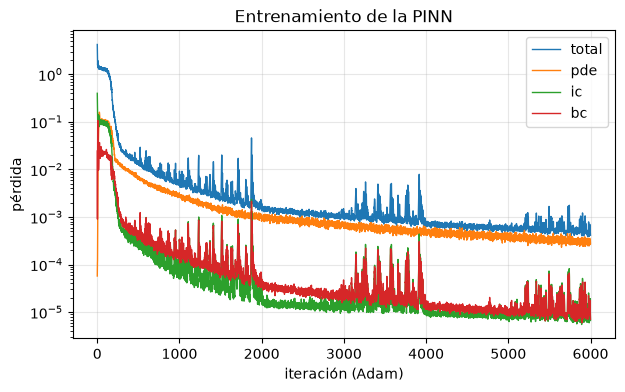

In [23]:
# ============================================================
# PINN para la ecuación de calor 2D (PyTorch)
# ============================================================
# Variables adimensionales para que la red trabaje con números de orden 1:
#   ξ = x/L,  η = y/L,  τ = t/t_f,   θ = (T - T_b)/ΔT
# La ecuación queda   ∂θ/∂τ = κ (θ_ξξ + θ_ηη),   con κ = α t_f / L².
#   frontera: θ = 0 ;  inicial: θ(ξ, η, 0) = sin(πξ) sin(πη)
import torch, time
torch.manual_seed(0)
kappa = params["alpha"] * tiempo_final / Lx**2
print(f"κ = α t_f / L² = {kappa}")

class PINN(torch.nn.Module):
    def __init__(self, ancho=40, capas=4):
        super().__init__()
        mods, d_in = [], 3
        for _ in range(capas):
            mods += [torch.nn.Linear(d_in, ancho), torch.nn.Tanh()]
            d_in = ancho
        mods.append(torch.nn.Linear(d_in, 1))
        self.red = torch.nn.Sequential(*mods)
    def forward(self, xi, eta, tau):
        return self.red(torch.cat([xi, eta, tau], dim=1))

def residual(red, xi, eta, tau):
    th = red(xi, eta, tau)
    g = lambda out, var: torch.autograd.grad(out, var, torch.ones_like(out), create_graph=True)[0]
    th_t = g(th, tau)
    th_xx = g(g(th, xi), xi)
    th_yy = g(g(th, eta), eta)
    return th_t - kappa * (th_xx + th_yy)

def puntos_interiores(n):
    return [torch.rand(n, 1, requires_grad=True) for _ in range(3)]

def puntos_frontera(n):
    s = torch.rand(n, 1); tau = torch.rand(n, 1)
    lado = torch.randint(0, 4, (n, 1))
    xi = torch.where(lado == 0, torch.zeros_like(s), torch.where(lado == 1, torch.ones_like(s), s))
    eta = torch.where(lado == 2, torch.zeros_like(s), torch.where(lado == 3, torch.ones_like(s), s))
    xi = torch.where((lado == 2) | (lado == 3), s, xi)
    return xi, eta, tau

def puntos_iniciales(n):
    xi, eta = torch.rand(n, 1), torch.rand(n, 1)
    return xi, eta, torch.zeros(n, 1), torch.sin(np.pi * xi) * torch.sin(np.pi * eta)

pinn = PINN()
opt = torch.optim.Adam(pinn.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2000, gamma=0.5)
historia_pinn = {"total": [], "pde": [], "ic": [], "bc": []}
t0 = time.time()
for it in range(6000):
    xi_r, eta_r, tau_r = puntos_interiores(2000)
    xi_b, eta_b, tau_b = puntos_frontera(500)
    xi_0, eta_0, tau_0, th_0 = puntos_iniciales(500)
    l_pde = (residual(pinn, xi_r, eta_r, tau_r)**2).mean()
    l_bc = (pinn(xi_b, eta_b, tau_b)**2).mean()
    l_ic = ((pinn(xi_0, eta_0, tau_0) - th_0)**2).mean()
    loss = l_pde + 10 * l_bc + 10 * l_ic
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    for k_, v_ in zip(historia_pinn, [loss, l_pde, l_ic, l_bc]):
        historia_pinn[k_].append(v_.item())
    if (it + 1) % 1000 == 0:
        print(f"it {it+1:5d}  pérdida = {loss.item():.2e}  (PDE {l_pde.item():.1e}, IC {l_ic.item():.1e}, BC {l_bc.item():.1e})  {time.time()-t0:.0f} s")

# Afinamiento con L-BFGS sobre un conjunto fijo de puntos
xi_r, eta_r, tau_r = puntos_interiores(4000); xi_b, eta_b, tau_b = puntos_frontera(1000)
xi_0, eta_0, tau_0, th_0 = puntos_iniciales(1000)
lbfgs = torch.optim.LBFGS(pinn.parameters(), lr=1.0, max_iter=500, history_size=50, line_search_fn="strong_wolfe")
def cierre():
    lbfgs.zero_grad()
    l = ((residual(pinn, xi_r, eta_r, tau_r)**2).mean() + 10 * (pinn(xi_b, eta_b, tau_b)**2).mean()
         + 10 * ((pinn(xi_0, eta_0, tau_0) - th_0)**2).mean())
    l.backward(); return l
l_final = lbfgs.step(cierre)
print(f"Después de L-BFGS: pérdida = {cierre().item():.2e}   tiempo total {time.time()-t0:.0f} s")

plt.figure(figsize=(7, 4))
for k_ in historia_pinn:
    plt.semilogy(historia_pinn[k_], label=k_, lw=1)
plt.xlabel("iteración (Adam)"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=.3); plt.title("Entrenamiento de la PINN")
plt.show()

In [24]:
import numpy as np
import plotly.graph_objects as go


def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    for j, k in enumerate(indices):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="Jet",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [°C]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} °C"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

PINN: error máximo = 0.520 °C   error medio = 0.037 °C   error L2 relativo (sobre T - T_b) = 0.16 %
Diferencias finitas: error máximo = 0.0610 °C


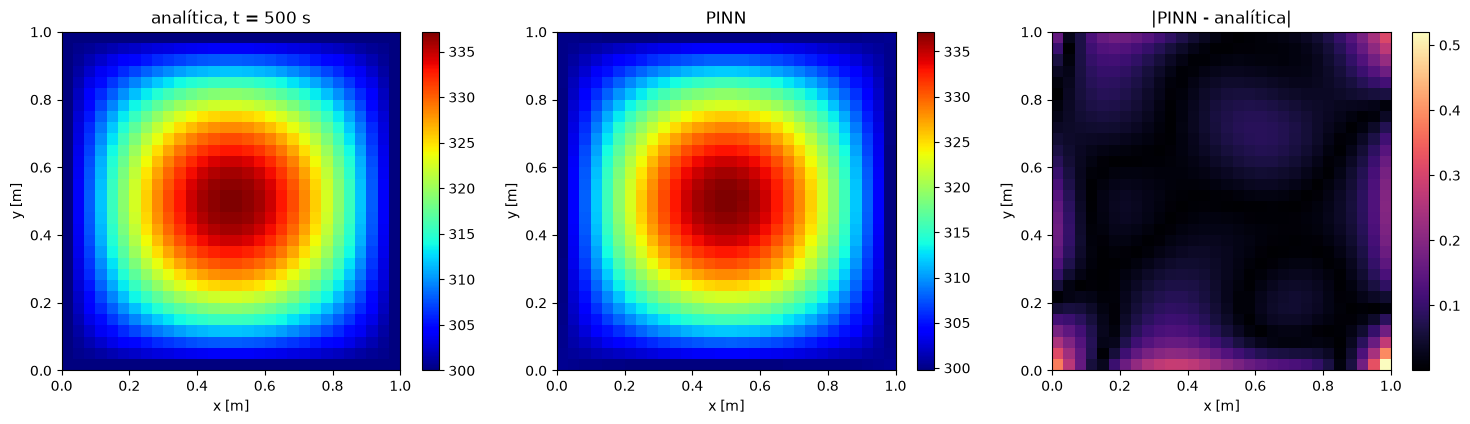

In [25]:
# Evaluar la PINN en la misma malla (x, y, t) y comparar con la solución analítica
def evaluar_pinn(Xg, Yg, tk):
    with torch.no_grad():
        xi = torch.tensor(Xg.ravel() / Lx, dtype=torch.float32)[:, None]
        eta = torch.tensor(Yg.ravel() / Ly, dtype=torch.float32)[:, None]
        tau = torch.full_like(xi, tk / tiempo_final)
        th = pinn(xi, eta, tau).numpy().reshape(Xg.shape)
    return Tb + delta_T * th

Temperatura_PINN = np.array([evaluar_pinn(X, Y, tk) for tk in t])
err_pinn = np.abs(Temperatura_PINN - T_exacta)
l2_rel = np.linalg.norm(Temperatura_PINN - T_exacta) / np.linalg.norm(T_exacta - Tb)
print(f"PINN: error máximo = {err_pinn.max():.3f} °C   error medio = {err_pinn.mean():.3f} °C   "
      f"error L2 relativo (sobre T - T_b) = {100*l2_rel:.2f} %")
print(f"Diferencias finitas: error máximo = {err_fd.max():.4f} °C")

k_fin = nt - 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, Z_, tit in zip(ax, [T_exacta[k_fin], Temperatura_PINN[k_fin], err_pinn[k_fin]],
                       [f"analítica, t = {t[k_fin]:.0f} s", "PINN", "|PINN - analítica|"]):
    im_ = a_.imshow(Z_.T, origin="lower", extent=[0, Lx, 0, Ly], cmap="jet" if "|" not in tit else "magma")
    a_.set_title(tit); a_.set_xlabel("x [m]"); a_.set_ylabel("y [m]"); fig.colorbar(im_, ax=a_)
plt.tight_layout(); plt.show()

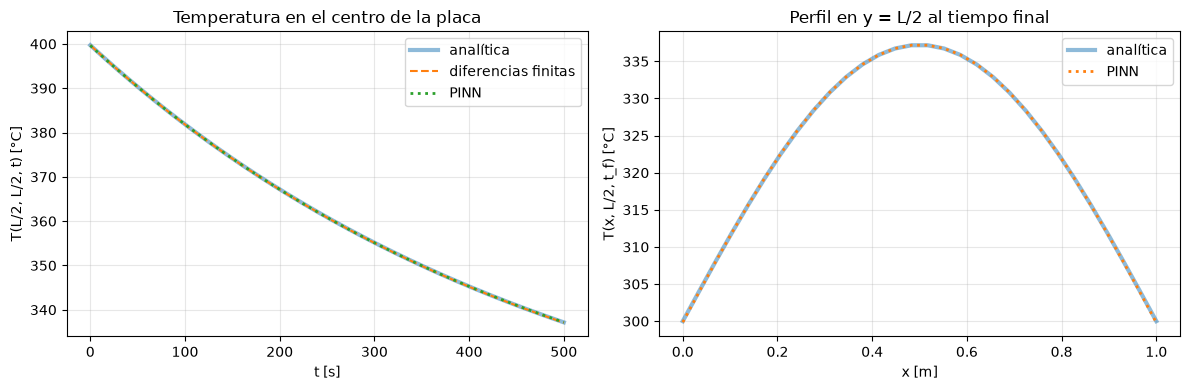

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, T_exacta[:, ic, jc], lw=3, alpha=0.5, label="analítica")
ax[0].plot(t, Temperatura[:, ic, jc], "--", label="diferencias finitas")
ax[0].plot(t, Temperatura_PINN[:, ic, jc], ":", lw=2, label="PINN")
ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("T(L/2, L/2, t) [°C]"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("Temperatura en el centro de la placa")
ax[1].plot(x, T_exacta[k_fin, :, jc], lw=3, alpha=0.5, label="analítica")
ax[1].plot(x, Temperatura_PINN[k_fin, :, jc], ":", lw=2, label="PINN")
ax[1].set_xlabel("x [m]"); ax[1].set_ylabel("T(x, L/2, t_f) [°C]"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title("Perfil en y = L/2 al tiempo final")
plt.tight_layout(); plt.show()

In [27]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
fig.show()

In [28]:
fig = graficar_planos(Temperatura_PINN, Lx, Ly, tiempos=t, n_planos=10, opacidad=0.5)
fig.show()


In [29]:
np.shape(Temperatura)

(188, 30, 30)

In [30]:
len(t)

188

In [31]:

n_frames =len(Temperatura)# min(100), Temperatura.shape[0])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="jet",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [°C]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=1,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))

## Conclusiones

- **Diferenciación automática.** Propagar pares (valor, derivada) con la regla de la cadena da derivadas exactas, hasta el redondeo de máquina, sin aproximar con diferencias finitas. Esto se verificó con $\sin(\cos x^2)$ y con dos neuronas $\tanh$, comparando con la derivada analítica, con diferencias finitas y con `torch.autograd`. Hubo que corregir las funciones `seno` y `coseno` del notebook original.
- **Diferencias finitas.** Con Euler explícito y $\Delta t$ al 90 % del límite de estabilidad, el error frente a la solución analítica es de centésimas de °C.
- **PINN.** La red $\theta(\xi,\eta,\tau)$ (4 capas ocultas de 40 neuronas $\tanh$) nunca ve la solución. Solo minimiza el residual de la ecuación de calor, calculado con autograd, más las condiciones inicial y de frontera. Aun así reproduce la solución analítica, con decaimiento $e^{-2\alpha\pi^2 t/L^2}$ y perfil $\sin(\pi x/L)\sin(\pi y/L)$: error máximo de **0.52 °C**, error medio de **0.04 °C** y error L2 relativo de **0.16 %**, sobre una diferencia de 100 °C. El afinamiento final con L-BFGS bajó la pérdida de $4\times10^{-4}$ a $3\times10^{-5}$. Se adimensionalizaron las variables ($\theta = (T-T_b)/\Delta T$, $\tau = t/t_f$, $\kappa = \alpha t_f/L^2 = 0.05$) para que todos los términos de la pérdida y las entradas de la red sean de orden 1; con $T \sim 300$ y $\alpha = 10^{-4}$ en unidades físicas, los términos tendrían escalas muy distintas.
- **Comparación.** Para este problema sencillo, las diferencias finitas son mucho más rápidas (menos de un segundo frente a unos 30 minutos de entrenamiento en CPU) y más precisas (error máximo de 0.06 °C). La PINN da una solución continua en $(x,y,t)$, sin malla, que se puede evaluar en cualquier punto. Además, el mismo marco permite resolver problemas inversos, por ejemplo estimar $\alpha$ a partir de mediciones de temperatura.
